# 16 확신도 기준("모른다" 모듈) 비교: 점수 종류와 sigmoid 출력

학습한 모델 뒤에 **"모른다" 모듈**(확신이 기준보다 낮으면 명령으로 받지 않음)을 붙일 때 **무엇을 확신도로 쓸지** 비교합니다. 11의 E26은 softmax 확률만 썼고, CNN은 이전 설정(EMA 없음)이었습니다. 여기서는 확정한 팀 모델 B(EMA, 30에폭, 마지막 에폭)와 기준선 A로, **같은 놓침에서 처음 듣는 단어 오작동**을 비교합니다.

| 번호 | 모델 | 출력 | 비고 |
|---|---|---|---|
| E33 | 팀 모델 B: 로그 멜 CNN, EMA, 30에폭, 마지막 에폭 | 11개 softmax | 14의 E32와 같은 학습 (다시 실행, 검산용) |
| E34 | 팀 모델 B: 같은 CNN·학습 | **10개 sigmoid** (명령어마다 1 대 나머지, "명령 아님"은 정답이 전부 0) | 바꾼 것은 출력과 손실 하나 |
| E35 | 기준선 A: whisper-base 고정 + Linear | 11개 softmax | 11의 E22(전부)와 같은 학습 |
| E36 | 기준선 A: 같은 특징 + Linear | **10개 sigmoid** | 바꾼 것은 출력과 손실 하나 |

확신도 점수 (모듈은 학습을 바꾸지 않고 판정만 바꿈)

| 점수 | 계산 | 확인하려는 것 |
|---|---|---|
| softmax 확률 | 명령어 10개 중 가장 큰 softmax 확률 | E26 방식 (비교 기준) |
| 온도 보정 softmax | softmax(출력 / T), T는 뺀 단어를 제외한 검증에서 NLL이 가장 작은 값 | "0.7 = 약 70% 정답"이 되게 맞추면 달라지는가 |
| softmax 전 최대값 | 명령어 출력 중 가장 큰 값 | 출력 크기 정보가 처음 듣는 단어를 더 잘 거르는가 (MaxLogit) |
| 차이 | 가장 큰 명령어 출력 − "명령 아님" 출력 | 기준점이 없는 softmax 전 값 대신 차이를 쓰면 |
| 선형 비율 ② (참고) | (출력 − 최소) / (최대 − 최소)로 바꾼 뒤 고른 명령이 차지하는 비율 | softmax 대신 선형으로 정규화하면 (나쁠 것으로 예상) |
| sigmoid 최대값 | E34·E36에서 명령어 출력 10개의 sigmoid 중 최대 | "명령 아님"을 한 클래스로 배우지 않으면 |

- **판정:** 11개 softmax 모델은 "명령 아님"이 가장 크지 않고 **점수 ≥ 기준**일 때만 명령으로 받습니다(E26과 같음). sigmoid 모델은 점수 ≥ 기준이면 받습니다. 기준 없음은 softmax는 가장 큰 출력, sigmoid는 0.5입니다.
- **기준 정하기:** 검증 명령어 녹음의 **놓침**(명령 아님 + 모른다)이 2 / 5 / 8 / 10% 이하가 되는 가장 엄격한 값입니다. 처음 듣는 단어(뺀 단어) 결과는 기준을 정하는 데 쓰지 않습니다. 참고로 **고정 0.7**(점수 종류와 상관없이 같은 숫자)도 함께 적습니다.
- **처음 듣는 단어 흉내:** 09·14와 같은 4묶음(묶음마다 "명령 아님" 단어 5개를 학습에서 뺌) × 시드 2개. 오작동은 **시드마다 4묶음의 뺀 단어 녹음(합쳐서 5,580개)을 합쳐 센 비율의 시드 평균**입니다(E26과 같은 방식, 14의 실행별 평균과는 조금 다름).
- **판정 기준 (결과를 보기 전에 정함):** 같은 놓침 목표에서 처음 듣는 단어 오작동이 softmax 확률보다 2%p 넘게 낮고 모든 시드에서 낮으면 "나음", 2%p 넘게 높고 모든 시드에서 높으면 "나쁨", 나머지는 "차이 없음".
- **부가 확인:** 명령어별 놓침이, 소리가 닮은 "명령 아님" 단어(one·nine·two·dog·house)를 학습에서 뺀 묶음에서 줄어드는지.
- 시험 묶음은 불러오지 않습니다.
- **예상 시간 (Kaggle T4):** B 학습 16번 × 30에폭 × 약 7초 ≈ 55분, A 머리 16번 ≈ 2분. Whisper 특징이 저장돼 있지 않으면 특징 뽑기 약 40분이 더 걸립니다(`RUN_A = False`면 A를 건너뜀). 학습 결과(검증 출력)는 `CACHE_DIR`에 저장하므로 분석 셀만 다시 돌릴 때는 학습을 건너뜁니다.
- `SMOKE = True`는 끝까지 도는지만 확인합니다(숫자를 쓰지 않음).
- **남는 것:** `results/16_operating_points.csv`(모든 모델·점수·조건의 지표), `figs/16_tradeoff_curves.png`(놓침-오작동 곡선). 실행 후 노트북은 `16_확신도기준_비교_결과.ipynb`로 저장합니다.
- **참고한 방법:** softmax 최대 확률(Hendrycks & Gimpel, ICLR 2017), MaxLogit(Hendrycks et al., ICML 2022), 온도 보정(Guo et al., ICML 2017), 1 대 나머지 sigmoid로 처음 보는 입력 거르기(Shu et al., DOC, EMNLP 2017).

In [1]:
# 셀 1. 설정과 버전
import os, sys, time, random, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
import matplotlib.pyplot as plt
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

SMOKE = False                  # True: 단어마다 몇 개만, 짧게 (결과 숫자는 쓰지 않음)
USE_DRIVE = False              # True: Colab에서 Google Drive를 연결해 10·11·15에서 저장한 특징을 다시 씀
RUN_A = True                   # False: 기준선 A(E35·E36)를 건너뜀 (Whisper 특징이 없으면 약 40분 절약)
RUN_SIGMOID = True             # False: sigmoid 출력(E34·E36)을 건너뜀
SEEDS = [0, 1]
FOLD_SEED = 0
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
AUX = ["bed", "bird", "cat", "dog", "happy", "house", "marvin", "sheila", "tree", "wow"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
N_CMD = len(COMMANDS)
WHISPER = "openai/whisper-base"
N_KEEP = 50                    # Whisper 인코더 1칸 = 20 ms → 앞 50칸 = 1초
B_EPOCHS, B_LR, B_BATCH, EMA_DECAY = 30, 1e-3, 256, 0.999     # 14의 E32와 같음
B_CHANNELS = [16, 32, 64, 128]
LIN_EPOCHS, LIN_LR, LIN_BATCH = 30, 1e-3, 512                 # 11의 E22와 같음
TARGETS = [0.02, 0.05, 0.08, 0.10]                            # 검증 명령어 놓침 목표
FIXED = 0.7                                                   # 참고: 점수 종류와 상관없이 같은 숫자로 고정한 기준

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
DTYPE = torch.float16 if AMP else torch.float32
if SMOKE:
    B_EPOCHS, LIN_EPOCHS, SEEDS = 2, 2, [0]
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR,
      "| A", RUN_A, "| sigmoid", RUN_SIGMOID)
T_START = time.time()

python 3.13.16 | torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | pandas 2.2.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 cache | A True | sigmoid True


In [2]:
# 셀 2. 데이터 (08·09·14와 같은 구성) + 단어 4묶음 (09·14와 같은 배정)
os.makedirs(DATA_ROOT, exist_ok=True)
sc = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")    # 공식 학습 목록 (검증·시험 목록 제외)
BASE_DIR = os.path.dirname(sc._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 불러오지 않음
base_train = table[table.split == "train"]

rows = []
for i in range(len(sc)):
    path, _, word, spk, _ = sc.get_metadata(i)
    if word in COMMANDS or word in UNSEEN:
        continue
    rows.append({"split": "train", "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                 "label": OTHER, "group": "seen_other", "start": 0, "gain": 1.0})
pool = pd.DataFrame(rows)
assert sorted(pool.word.unique()) == sorted(DIGITS + AUX)
used = set(base_train[base_train.group == "seen_other"].path)
assert used <= set(pool.path)
rng = np.random.default_rng(0)
pool["first"] = ~pool.path.isin(used)                        # 08과 같은 순서 (저장된 특징과 행이 맞게)
pool["rnd"] = rng.random(len(pool))
pool = pool.sort_values(["word", "first", "rnd"]).drop(columns=["first", "rnd"])
pool["rank"] = pool.groupby("word").cumcount()
rest = base_train[base_train.group != "seen_other"].assign(rank=-1)
if SMOKE:
    rest = rest.groupby("label").head(10)
    pool = pool[pool["rank"] < 20]
train_all = pd.concat([rest, pool], ignore_index=True)
val = table[table.split == "val"].reset_index(drop=True)
if SMOKE:
    val = val.groupby(["label", "group", "word"], group_keys=False).sample(frac=1.0, random_state=0)
    val = val.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
L2I = {l: i for i, l in enumerate(LABELS)}
OTHER_I = L2I[OTHER]
Y_ALL = torch.tensor(train_all.label.map(L2I).values)
Y_VAL = torch.tensor(val.label.map(L2I).values)
Y_VAL_NP = Y_VAL.numpy()
IS_CMD_VAL = Y_VAL_NP != OTHER_I
VAL_WORD = val.word.to_numpy(copy=True)
GROUP_VAL = val.group.to_numpy(copy=True)

# 검사: 학습·검증 화자 겹침 없음(단어 녹음), 처음 듣는 단어 5개는 학습·검증에 없음
spk_tr = set(train_all[train_all.group != "noise"].speaker); spk_va = set(val[val.group != "noise"].speaker)
assert not (spk_tr & spk_va), "학습·검증 화자가 겹침"
assert not (set(train_all.word) | set(val.word)) & set(UNSEEN), "처음 듣는 단어가 학습·검증에 있음"

# 단어 4묶음: 숫자 3·3·2·2개 + 보조 단어 2·2·3·3개
fr = np.random.default_rng(FOLD_SEED)
d, a = list(fr.permutation(DIGITS)), list(fr.permutation(AUX))
FOLDS, i_d, i_a = [], 0, 0
for nd, na in [(3, 2), (3, 2), (2, 3), (2, 3)]:
    FOLDS.append([str(w) for w in sorted(d[i_d:i_d + nd]) + sorted(a[i_a:i_a + na])])
    i_d += nd; i_a += na
assert sorted(sum(FOLDS, [])) == sorted(DIGITS + AUX)

def train_mask(held):
    """'명령 아님' 단어는 녹음 전부(E16·E32 조건), held 단어만 학습에서 뺌"""
    return (~train_all.word.isin(held)).to_numpy(copy=True)

print(f"학습 {len(train_all):,}개 / 검증 {len(val):,}개 | 검증 중 '명령 아님' {(~IS_CMD_VAL).mean():.1%} | 학습·검증 화자 겹침 0명, 처음 듣는 단어 없음 확인")
for f, held in enumerate(FOLDS):
    m = train_mask(held)
    print(f"묶음 {f + 1}: 뺄 단어 {held} → 학습 {m.sum():,}개, 검증에서 뺀 단어 {np.isin(VAL_WORD, held).sum():,}개")

100%|██████████| 2.26G/2.26G [00:30<00:00, 78.4MB/s]


학습 79,392개 / 검증 9,400개 | 검증 중 '명령 아님' 60.6% | 학습·검증 화자 겹침 0명, 처음 듣는 단어 없음 확인
묶음 1: 뺄 단어 ['four', 'six', 'two', 'cat', 'wow'] → 학습 66,857개, 검증에서 뺀 단어 1,469개
묶음 2: 뺄 단어 ['five', 'seven', 'three', 'dog', 'marvin'] → 학습 66,560개, 검증에서 뺀 단어 1,502개
묶음 3: 뺄 단어 ['nine', 'zero', 'bed', 'happy', 'tree'] → 학습 68,339개, 검증에서 뺀 단어 1,331개
묶음 4: 뺄 단어 ['eight', 'one', 'bird', 'house', 'sheila'] → 학습 68,189개, 검증에서 뺀 단어 1,278개


In [3]:
# 셀 3. 소리 읽기와 저장 도구 (06과 같은 규칙). 새로 저장하는 특징에는 행 키(경로·시작·음량)를 함께 넣어 불러올 때 순서를 확인
def load_row(r):
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def loader(df, batch):
    workers = 2 if os.name != "nt" else 0
    return torch.utils.data.DataLoader(Rows(df), batch_size=batch, shuffle=False, num_workers=workers,
                                       multiprocessing_context="fork" if workers else None, collate_fn=lambda b: np.stack(b))

def keys(df):
    return [(str(p), int(s), round(float(g), 6)) for p, s, g in zip(df.path, df.start, df.gain)]

def cached(name, fn, row_keys=None):
    """저장된 것이 있으면 다시 씀. row_keys가 있으면 저장된 행 순서가 지금 목록과 같은지 확인
    (08·10·11·15에서 저장한 것은 키가 없어 개수만 확인)"""
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        if row_keys is not None and "keys" in d:
            assert d["keys"] == row_keys, f"{name}: 저장된 행 순서가 지금 목록과 다름 → {path}를 지우고 다시 계산"
            how = "행 키 일치"
        else:
            how = "행 키 없음, 개수만 확인"
        print(f"  {name}: 저장된 것 사용 ({how}, 처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    if row_keys is not None:
        d["keys"] = row_keys
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

In [4]:
# 셀 4. 특징: B는 로그 멜(64 × 101), A는 whisper-base 마지막 층(30초 입력, 앞 1초 평균). 저장한 것이 있으면 다시 씀
mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)
def spec(df, name):
    def run():
        M, t0 = [], time.time()
        with torch.no_grad():
            for x in loader(df, 256):
                M.append(to_db(mel(torch.from_numpy(x).to(device))).half().cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "sec": time.time() - t0}
        print(f"  {name}: 로그 멜 {tuple(d['mel'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run, keys(df))
MEL_ALL = spec(train_all, "spec16_train" if SMOKE else "spec08_train_pool")["mel"]
MEL_VAL = spec(val, "spec16_val" if SMOKE else "spec11_val")["mel"]
assert len(MEL_ALL) == len(train_all) and len(MEL_VAL) == len(val)

if RUN_A:
    import transformers
    from transformers import WhisperFeatureExtractor, WhisperModel
    print("transformers", transformers.__version__)
    def whisper_feats(df, name):
        def run():
            fe = WhisperFeatureExtractor.from_pretrained(WHISPER)
            whisper = WhisperModel.from_pretrained(WHISPER, torch_dtype=DTYPE).to(device).eval()
            X, t0 = [], time.time()
            with torch.no_grad():
                for x in loader(df, 32):
                    f = fe(list(x), sampling_rate=SR, return_tensors="pt").input_features.to(device, DTYPE)
                    hs = whisper.encoder(f, output_hidden_states=True).hidden_states[1:]
                    X.append(torch.stack([h[:, :N_KEEP].mean(1) for h in hs], 1).half().cpu())   # (B, 층, 차원)
            d = {"X": torch.cat(X), "sec": time.time() - t0}
            print(f"  {name}: {tuple(d['X'].shape)} ({d['sec']:.0f}초)")
            return d
        d = cached(name, run, keys(df))
        assert len(d["X"]) == len(df), f"{name}: 저장된 개수 {len(d['X'])} ≠ 목록 {len(df)}"
        return d
    # 07에서 저장한 학습 34,829개(목록 파일 순서) + 10에서 저장한 추가분을 학습 데이터 순서로 이어 붙임 (15와 같음)
    wtrain = base_train.reset_index(drop=True)
    if SMOKE:
        wtrain = wtrain.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
    d_tr = whisper_feats(wtrain, "whisper16_train" if SMOKE else "whisper_base11_train")
    d_va = whisper_feats(val, "whisper16_val" if SMOKE else "whisper_base11_val")
    W_IDX = {k: i for i, k in enumerate(keys(wtrain))}
    src = [W_IDX.get(k, -1) for k in keys(train_all)]
    have = np.array([j >= 0 for j in src])
    d_ex = whisper_feats(train_all[~have].reset_index(drop=True), "whisper16_extra" if SMOKE else "whisper_base11_extra")
    WX_ALL = torch.empty(len(train_all), d_tr["X"].shape[-1], dtype=torch.float16)
    WX_ALL[torch.from_numpy(have)] = d_tr["X"][[j for j in src if j >= 0], -1]
    WX_ALL[torch.from_numpy(~have)] = d_ex["X"][:, -1]
    WX_VA = d_va["X"][:, -1]
    print(f"Whisper 마지막 층 특징: 학습 {tuple(WX_ALL.shape)}, 검증 {tuple(WX_VA.shape)}")

  spec08_train_pool: 로그 멜 (79392, 1, 64, 101) (46초)
  spec11_val: 로그 멜 (9400, 1, 64, 101) (9초)
transformers 5.22.1


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  290MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

  whisper_base11_train: (34829, 6, 512) (1319초)


Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

  whisper_base11_val: (9400, 6, 512) (352초)


Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

  whisper_base11_extra: (44563, 6, 512) (1692초)
Whisper 마지막 층 특징: 학습 (79392, 512), 검증 (9400, 512)


In [5]:
# 셀 5. 학습 함수: B(CNN, EMA, 마지막 에폭)와 A(Whisper 특징 위 Linear, 뺀 단어 제외 검증 F1 최고 에폭). 출력은 11개 softmax 또는 10개 sigmoid
class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))

def n_out(head):
    return K if head == "softmax" else N_CMD

def loss_fn(out, y, head):
    """softmax: 11개 교차 엔트로피 / sigmoid: 명령어 10개 각각 이진 교차 엔트로피, '명령 아님'은 정답 벡터가 전부 0"""
    if head == "softmax":
        return nn.functional.cross_entropy(out, y)
    target = nn.functional.one_hot(y.clamp(max=N_CMD - 1), N_CMD).float() * (y != OTHER_I).unsqueeze(1)
    return nn.functional.binary_cross_entropy_with_logits(out, target)

def to_pred(out, head):
    """기준 없는 기본 판정: softmax는 11개 중 최대, sigmoid는 가장 큰 확률이 0.5 이상이면 그 명령"""
    if head == "softmax":
        return out.argmax(1)
    c = out.argmax(1)
    return torch.where(torch.sigmoid(out.max(1).values) >= 0.5, c, torch.full_like(c, OTHER_I))

def val_f1(pred, held):
    """뺀 단어를 제외한 검증의 매크로 F1 (11개 클래스, 에폭 선택·진행 표시용)"""
    p, t = pred.cpu().numpy(), Y_VAL_NP
    sel = ~np.isin(VAL_WORD, held)
    cm = np.bincount(t[sel] * K + p[sel], minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    return float(np.mean(2 * prec * rec / np.maximum(prec + rec, 1e-12)))

def train_b(mask, held, seed, head):
    """14의 train_fold(EMA, 학습률 고정, 30에폭, 마지막 에폭)와 같은 학습. 출력 수와 손실만 head에 따라 다름"""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN(n_classes=n_out(head)).to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    ema = AveragedModel(cnn, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, t0 = [], time.time()
    for ep in range(B_EPOCHS):
        cnn.train()
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = loss_fn(cnn(Xtr[idx]).float(), Ytr[idx], head)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            ema.update_parameters(cnn)
        if (ep + 1) % 10 == 0 or ep + 1 == B_EPOCHS:
            ema.eval()
            with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                out = torch.cat([ema(Xva[i:i + 1024]) for i in range(0, len(Xva), 1024)]).float()
            f1 = val_f1(to_pred(out, head), held)
            hist.append({"epoch": ep + 1, "f1": f1})
            print(f"    [B {head} 시드 {seed}] 에폭 {ep + 1:2d}/{B_EPOCHS} | F1(뺀 단어 제외) {f1:.4f} | {time.time() - t0:.0f}초 경과")
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    return {"logits": out.cpu(), "epoch": B_EPOCHS, "f1": f1, "sec": time.time() - t0, "hist": hist}

def train_a(mask, held, seed, head):
    """11의 train_head(Linear, Adam 1e-3, 배치 512, 30에폭)와 같은 학습. 뺀 단어 제외 검증 F1이 가장 높은 에폭의 출력을 씀"""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    X = WX_ALL[m].float().to(device); Y = Y_ALL[m].to(device)
    mu, sd = X.mean(0), X.std(0) + 1e-6
    X, Xva = (X - mu) / sd, (WX_VA.float().to(device) - mu) / sd
    lin = nn.Linear(X.shape[1], n_out(head)).to(device)
    opt = torch.optim.Adam(lin.parameters(), lr=LIN_LR)
    best, t0 = None, time.time()
    for ep in range(LIN_EPOCHS):
        lin.train()
        perm = torch.randperm(len(X), device=device)
        for i in range(0, len(X), LIN_BATCH):
            idx = perm[i:i + LIN_BATCH]
            loss = loss_fn(lin(X[idx]), Y[idx], head)
            opt.zero_grad(); loss.backward(); opt.step()
        lin.eval()
        with torch.no_grad():
            out = lin(Xva).float()
        f1 = val_f1(to_pred(out, head), held)
        if best is None or f1 > best["f1"]:
            best = {"logits": out.cpu(), "epoch": ep + 1, "f1": f1}
    best["sec"] = time.time() - t0
    best["hist"] = []
    return best

In [6]:
# 셀 6. 학습: (B, A) × (softmax, sigmoid) × 4묶음 × 시드. 검증 출력(softmax 전 값)을 저장하고, 같은 설정으로 저장된 것이 있으면 다시 씀
JOBS = [("B", "softmax", "E33"), ("B", "sigmoid", "E34"), ("A", "softmax", "E35"), ("A", "sigmoid", "E36")]
JOBS = [j for j in JOBS if (RUN_A or j[0] == "B") and (RUN_SIGMOID or j[1] == "softmax")]
RUNS = []
t_all = time.time()
for model, head, eid in JOBS:
    config = {"model": model, "head": head, "seeds": SEEDS, "folds": FOLDS, "n_train": len(train_all), "n_val": len(val),
              "epochs": B_EPOCHS if model == "B" else LIN_EPOCHS, "ema": EMA_DECAY if model == "B" else 0.0}
    path = os.path.join(CACHE_DIR, f"16_runs_{model}_{head}{'_smoke' if SMOKE else ''}.pt")
    saved = torch.load(path) if os.path.exists(path) else None
    if saved is not None and saved["config"] == config:
        runs = saved["runs"]
        print(f"{eid} ({model}, {head}): 저장된 학습 결과 사용 ({len(runs)}번)")
    else:
        runs = []
        for f, held in enumerate(FOLDS):
            mask = train_mask(held)
            for seed in SEEDS:
                print(f"{eid} ({model}, {head}) 묶음 {f + 1} 시드 {seed} 시작 (학습 {mask.sum():,}개, 전체 {time.time() - t_all:.0f}초 경과)")
                r = (train_b if model == "B" else train_a)(mask, held, seed, head)
                runs.append({"fold": f + 1, "seed": seed, "held": held, **r})
                print(f"  → {r['epoch']}에폭 출력 사용 | F1(뺀 단어 제외) {r['f1']:.4f} | {r['sec']:.0f}초")
        os.makedirs(CACHE_DIR, exist_ok=True)
        torch.save({"config": config, "runs": runs}, path)
    RUNS += [{"model": model, "head": head, "eid": eid, **r} for r in runs]
print(f"학습 끝: {len(RUNS)}번, {time.time() - t_all:.0f}초")

E33 (B, softmax) 묶음 1 시드 0 시작 (학습 66,857개, 전체 0초 경과)
    [B softmax 시드 0] 에폭 10/30 | F1(뺀 단어 제외) 0.8053 | 66초 경과
    [B softmax 시드 0] 에폭 20/30 | F1(뺀 단어 제외) 0.9481 | 130초 경과
    [B softmax 시드 0] 에폭 30/30 | F1(뺀 단어 제외) 0.9502 | 195초 경과
  → 30에폭 출력 사용 | F1(뺀 단어 제외) 0.9502 | 195초
E33 (B, softmax) 묶음 1 시드 1 시작 (학습 66,857개, 전체 203초 경과)
    [B softmax 시드 1] 에폭 10/30 | F1(뺀 단어 제외) 0.4557 | 65초 경과
    [B softmax 시드 1] 에폭 20/30 | F1(뺀 단어 제외) 0.9438 | 129초 경과
    [B softmax 시드 1] 에폭 30/30 | F1(뺀 단어 제외) 0.9480 | 193초 경과
  → 30에폭 출력 사용 | F1(뺀 단어 제외) 0.9480 | 193초
E33 (B, softmax) 묶음 2 시드 0 시작 (학습 66,560개, 전체 401초 경과)
    [B softmax 시드 0] 에폭 10/30 | F1(뺀 단어 제외) 0.7894 | 64초 경과
    [B softmax 시드 0] 에폭 20/30 | F1(뺀 단어 제외) 0.9495 | 128초 경과
    [B softmax 시드 0] 에폭 30/30 | F1(뺀 단어 제외) 0.9496 | 192초 경과
  → 30에폭 출력 사용 | F1(뺀 단어 제외) 0.9496 | 192초
E33 (B, softmax) 묶음 2 시드 1 시작 (학습 66,560개, 전체 599초 경과)
    [B softmax 시드 1] 에폭 10/30 | F1(뺀 단어 제외) 0.4653 | 64초 경과
    [B softmax 시드 1] 에폭 20/30 | F1(뺀 단어 제외) 0.9

In [7]:
# 셀 7. "모른다" 모듈: 점수 계산, 기준 정하기(검증 명령어의 놓침만 봄), 판정과 지표
SCORES = {"softmax": ["prob", "prob_T", "logit", "margin", "minmax"], "sigmoid": ["sigmoid"]}
SCORE_NAME = {"prob": "softmax 확률 (E26 방식)", "prob_T": "온도 보정 softmax", "logit": "softmax 전 최대값",
              "margin": "차이 (최고 명령 − 명령 아님)", "minmax": "선형 비율 ② (참고)", "sigmoid": "sigmoid 최대값"}

def softmax_np(a):
    e = np.exp(a - a.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)

def fit_temperature(z, sel):
    """뺀 단어를 제외한 검증 녹음(sel)에서 NLL이 가장 작은 온도 T (0.05~20 격자 탐색, 끝에 걸리면 알림)"""
    zs, ys = z[sel], Y_VAL_NP[sel]
    grid = np.exp(np.linspace(np.log(0.05), np.log(20.0), 241))
    best_T, best_nll = 1.0, np.inf
    for T in grid:
        s = zs / T
        mx = s.max(1)
        nll = float(np.mean(np.log(np.exp(s - mx[:, None]).sum(1)) + mx - s[np.arange(len(ys)), ys]))
        if nll < best_nll:
            best_T, best_nll = float(T), nll
    if best_T in (grid[0], grid[-1]):
        print(f"  주의: 온도 T가 격자 끝({best_T:.2f})에 걸림 → 온도 보정 결과는 참고만")
    return best_T

def prepare(run):
    """실행 하나의 검증 출력 → 고른 명령, 기준 없이도 명령으로 받는지, 점수들 (점수가 클수록 '명령이라고 확신')"""
    z = run["logits"].double().numpy()
    held = np.isin(VAL_WORD, run["held"])
    c = z[:, :N_CMD].argmax(1)
    p = {"c": c, "held": held, "known": (GROUP_VAL == "seen_other") & ~held, "noise": GROUP_VAL == "noise", "s": {}}
    if run["head"] == "softmax":
        best = z[:, :N_CMD].max(1)
        p["base"] = z.argmax(1) != OTHER_I                 # "명령 아님"이 가장 크면 기준과 상관없이 명령 아님
        p["T"] = fit_temperature(z, ~held)
        p["s"]["prob"] = softmax_np(z)[:, :N_CMD].max(1)
        p["s"]["prob_T"] = softmax_np(z / p["T"])[:, :N_CMD].max(1)
        p["s"]["logit"] = best
        p["s"]["margin"] = best - z[:, OTHER_I]
        r = (z - z.min(1, keepdims=True)) / np.maximum(np.ptp(z, axis=1, keepdims=True), 1e-12)
        p["s"]["minmax"] = r[np.arange(len(z)), c] / np.maximum(r.sum(1), 1e-12)
        p["tau0"] = -np.inf                                # 기준 없음
    else:
        p["base"] = np.ones(len(z), bool)                  # 출력 10개: 점수만으로 판정
        p["s"]["sigmoid"] = 0.5 * (1 + np.tanh(z[:, :N_CMD].max(1) / 2))   # sigmoid (큰 값에서 넘치지 않게)
        p["tau0"] = 0.5                                    # 기준 없음 = BCE의 기본 판정 0.5
    return p

for r in RUNS:
    r["p"] = prepare(r)

def calibrate(p, kind, target):
    """검증 명령어의 놓침(명령 아님 + 모른다)이 target 이하인 가장 엄격한 기준. 뺀 단어는 보지 않음. 도달할 수 없으면 None"""
    room = int(target * IS_CMD_VAL.sum()) - int((IS_CMD_VAL & ~p["base"]).sum())   # 더 놓쳐도 되는 명령 수
    if room < 0:
        return None
    s = np.sort(p["s"][kind][IS_CMD_VAL & p["base"]])
    return float(s[room]) if room < len(s) else np.inf

def decide(p, kind, tau):
    """판정: 명령으로 받으면 고른 명령, 아니면 명령 아님('모른다' 포함)"""
    acc = p["base"] & (p["s"][kind] >= tau)
    return np.where(acc, p["c"], OTHER_I), acc

def point(p, kind, tau):
    """한 실행의 개수와 매크로 F1 (뺀 단어 제외, '모른다'는 '명령 아님'으로 셈)"""
    pred, acc = decide(p, kind, tau)
    t, ic, sel = Y_VAL_NP, IS_CMD_VAL, ~p["held"]
    cm = np.bincount(t[sel] * K + pred[sel], minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    return {"n_cmd": int(ic.sum()), "miss": int((~acc[ic]).sum()), "confuse": int((acc[ic] & (p["c"][ic] != t[ic])).sum()),
            "held_n": int(p["held"].sum()), "held_acc": int(acc[p["held"]].sum()),
            "known_n": int(p["known"].sum()), "known_acc": int(acc[p["known"]].sum()),
            "noise_n": int(p["noise"].sum()), "noise_acc": int(acc[p["noise"]].sum()),
            "f1": float(np.mean(2 * prec * rec / np.maximum(prec + rec, 1e-12))), "tau": tau}

def tau_for(p, kind, cond):
    return p["tau0"] if cond == "기준 없음" else FIXED if cond == "고정 0.7" else calibrate(p, kind, cond)

def summarize(model, head, kind, cond):
    """시드마다 4묶음의 개수를 합쳐 비율로 → 시드 평균. 한 실행이라도 목표 놓침에 도달하지 못하면 None"""
    per_seed = []
    for seed in SEEDS:
        pts = []
        for r in RUNS:
            if r["model"] == model and r["head"] == head and r["seed"] == seed:
                tau = tau_for(r["p"], kind, cond)
                if tau is None:
                    return None
                pts.append(point(r["p"], kind, tau))
        S = lambda k: sum(q[k] for q in pts)
        rate = lambda a, n: S(a) / S(n) if S(n) else float("nan")      # 녹음이 없는 무리는 nan
        per_seed.append({"miss": rate("miss", "n_cmd"), "confuse": rate("confuse", "n_cmd"),
                         "fa_held": rate("held_acc", "held_n"), "fa_known": rate("known_acc", "known_n"),
                         "fa_noise": rate("noise_acc", "noise_n"), "f1": float(np.mean([q["f1"] for q in pts])),
                         "tau": float(np.mean([q["tau"] for q in pts]))})
    d = pd.DataFrame(per_seed)
    out = d.mean().to_dict()
    out["fa_held_sd"] = float(d.fa_held.std()) if len(d) > 1 else float("nan")
    out["fa_held_seeds"] = d.fa_held.tolist()
    return out

print("점수 준비 끝:", ", ".join(f"{e} {sum(r['eid'] == e for r in RUNS)}번" for _, _, e in JOBS))

점수 준비 끝: E33 8번, E34 8번, E35 8번, E36 8번


In [8]:
# 셀 8. 결과 표: 같은 놓침에서 처음 듣는 단어 오작동 (낮을수록 좋음), 미리 정한 판정, 검산
CONDS = ["기준 없음", "고정 0.7"] + TARGETS
COND_NAME = lambda c: c if isinstance(c, str) else f"놓침 ≤ {c:.0%}"
COMBOS = [(model, head, kind) for model, head, _ in JOBS for kind in SCORES[head]]
EID = {(m, h): e for m, h, e in JOBS}
models = [m for m in ["A", "B"] if any(r["model"] == m for r in RUNS)]
fmtp = lambda v: "-" if pd.isna(v) else f"{v:.2%}"

rows = []
for model, head, kind in COMBOS:
    for cond in CONDS:
        s = summarize(model, head, kind, cond)
        rows.append({"번호": EID[(model, head)], "모델": model, "출력": head, "점수": SCORE_NAME[kind], "조건": COND_NAME(cond),
                     **({} if s is None else {k: v for k, v in s.items() if k != "fa_held_seeds"})})
res = pd.DataFrame(rows)
for col in ["miss", "confuse", "fa_held", "fa_known", "fa_noise", "f1", "tau", "fa_held_sd"]:
    if col not in res:
        res[col] = np.nan
os.makedirs("results", exist_ok=True)
res.to_csv(f"results/16_operating_points{'_smoke' if SMOKE else ''}.csv", index=False)

def cell(r):
    if pd.isna(r.fa_held):
        return "도달 불가"
    return f"{r.fa_held:.2%}" + (f" (놓침 {r.miss:.1%})" if r.조건 in ("기준 없음", "고정 0.7") else "")
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 40)
res["표"] = res.apply(cell, axis=1)
pivot = res.pivot_table(index=["번호", "점수"], columns="조건", values="표", aggfunc="first", sort=False)[[COND_NAME(c) for c in CONDS]]
print("[1] 처음 듣는 단어 오작동 (4묶음의 뺀 단어 녹음을 합쳐 센 비율, 시드 평균). '기준 없음'·'고정 0.7'은 괄호에 그때의 놓침")
print(pivot.to_string())

print("\n[2] 놓침 ≤ 5%에 맞춘 기준에서 다른 지표")
t5 = res[res.조건 == "놓침 ≤ 5%"]
print(pd.DataFrame({"번호": t5.번호, "점수": t5.점수, "기준(평균)": t5.tau.map(lambda v: "-" if pd.isna(v) else f"{v:.3f}"),
                    "놓침": t5.miss.map(fmtp), "명령 혼동": t5.confuse.map(fmtp),
                    "오작동(처음 듣는 단어)": [("도달 불가" if pd.isna(v) else f"{v:.2%}" + ("" if pd.isna(sd) else f" ± {sd:.2%}")) for v, sd in zip(t5.fa_held, t5.fa_held_sd)],
                    "오작동(들은 단어)": t5.fa_known.map(fmtp), "오작동(잡음)": t5.fa_noise.map(fmtp),
                    "매크로 F1": t5.f1.map(lambda v: "-" if pd.isna(v) else f"{v:.4f}")}).to_string(index=False))
print("± 는 시드 사이 표준편차")

print("\n[판정] 같은 놓침 목표에서 softmax 확률 대비: 2%p 넘게 낮고 모든 시드에서 낮으면 '나음', 2%p 넘게 높고 모든 시드에서 높으면 '나쁨', 나머지 '차이 없음'")
for model in models:
    if not any(m == model and h == "softmax" for m, h, _ in JOBS):
        continue
    tgt = next((t for t in [0.05, 0.08, 0.10] if summarize(model, "softmax", "prob", t) is not None), None)
    if tgt is None:
        print(f"  {model}: softmax 확률이 놓침 10% 안에 도달하지 못함"); continue
    ref = summarize(model, "softmax", "prob", tgt)
    for m_, head, kind in COMBOS:
        if m_ != model or (head, kind) == ("softmax", "prob"):
            continue
        s = summarize(model, head, kind, tgt)
        if s is None:
            print(f"  {model} 놓침 ≤ {tgt:.0%}: {SCORE_NAME[kind]} → 도달 불가"); continue
        diff = np.array(s["fa_held_seeds"]) - np.array(ref["fa_held_seeds"])
        word = "나음" if diff.mean() < -0.02 and (diff < 0).all() else "나쁨" if diff.mean() > 0.02 and (diff > 0).all() else "차이 없음"
        print(f"  {model} 놓침 ≤ {tgt:.0%}: {SCORE_NAME[kind]} {s['fa_held']:.2%} 대 softmax 확률 {ref['fa_held']:.2%} → {word} "
              f"(시드별 차이 {', '.join(f'{v * 100:+.2f}%p' for v in diff)})")

print("\n[검산] 기준 없음의 softmax 모델은 이전 결과와 같은 학습 (실행별 평균으로 비교, 같은 기기·버전이면 같은 값)")
for model, ref in [("B", "14의 E32: F1 0.9488, 뺀 단어 16.39%, 들은 단어 1.47%, 놓침 3.96% (Kaggle T4)"),
                   ("A", "11의 E22 전부: F1 0.9780, 뺀 단어 31.83%, 들은 단어 0.69%, 놓침 1.76% (Colab T4)")]:
    rs = [r for r in RUNS if r["model"] == model and r["head"] == "softmax"]
    if rs:
        q = pd.DataFrame([point(r["p"], "prob", r["p"]["tau0"]) for r in rs])
        print(f"  {model}: F1 {q.f1.mean():.4f}, 뺀 단어 {(q.held_acc / q.held_n).mean():.2%}, 들은 단어 {(q.known_acc / q.known_n).mean():.2%}, "
              f"놓침 {(q.miss / q.n_cmd).mean():.2%} | 참고 {ref}")
print("\n읽는 법: 같은 놓침 열에서 위아래를 비교. softmax 전 최대값·차이가 softmax 확률보다 낮으면 출력 크기 정보가 도움, "
      "선형 비율이 높으면 선형 정규화가 나쁨, sigmoid 모델이 낮으면 '명령 아님'을 한 클래스로 배우지 않는 편이 유리.")
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 시드 {SEEDS} | 검증 {len(val):,}개 | 시험 묶음은 쓰지 않음")

[1] 처음 듣는 단어 오작동 (4묶음의 뺀 단어 녹음을 합쳐 센 비율, 시드 평균). '기준 없음'·'고정 0.7'은 괄호에 그때의 놓침
조건                                  기준 없음             고정 0.7 놓침 ≤ 2% 놓침 ≤ 5% 놓침 ≤ 8% 놓침 ≤ 10%
번호  점수                                                                                       
E33 softmax 확률 (E26 방식)  16.42% (놓침 3.9%)    9.35% (놓침 7.2%)   도달 불가  13.49%   7.97%    5.92%
    온도 보정 softmax        16.42% (놓침 3.9%)    7.55% (놓침 8.2%)   도달 불가  13.29%   7.99%    5.83%
    softmax 전 최대값        16.42% (놓침 3.9%)    7.66% (놓침 8.6%)   도달 불가  13.38%   8.14%    6.16%
    차이 (최고 명령 − 명령 아님)   16.42% (놓침 3.9%)   13.15% (놓침 4.8%)   도달 불가  12.75%   7.02%    5.13%
    선형 비율 ② (참고)         16.42% (놓침 3.9%)  0.00% (놓침 100.0%)   도달 불가  13.39%   9.34%    8.15%
E34 sigmoid 최대값           9.81% (놓침 6.3%)    6.34% (놓침 8.4%)  26.65%  12.76%   6.97%    4.91%
E35 softmax 확률 (E26 방식)  31.16% (놓침 1.8%)   11.41% (놓침 3.5%)  25.68%   5.96%   1.43%    0.63%
    온도 보정 softmax        31.16% (놓침 1.8%)   11.53% (놓침 3.5%)  25.87%   6.08%

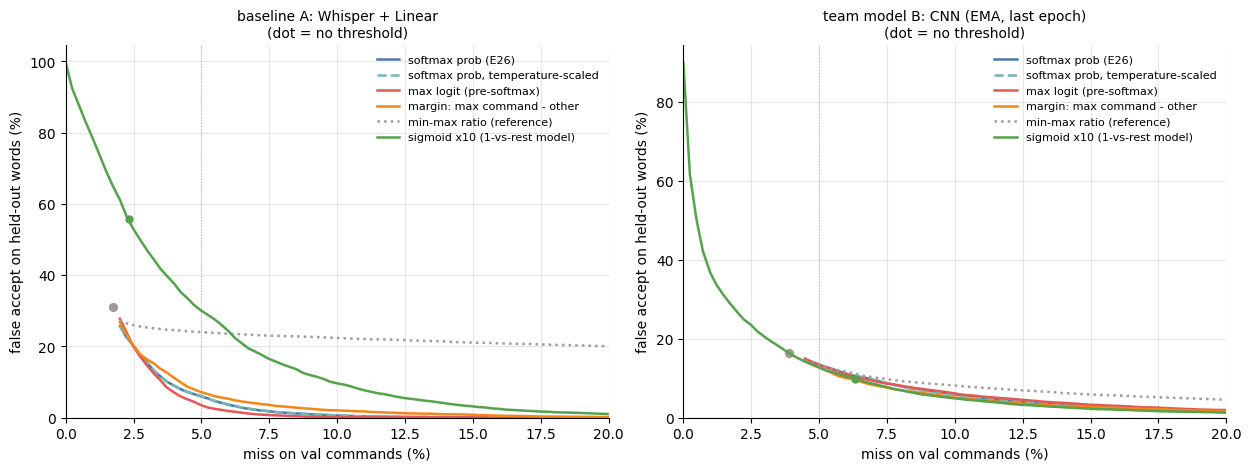

In [9]:
# 셀 9. 놓침-오작동 곡선: 검증 명령어 놓침 목표를 바꿔 가며 처음 듣는 단어 오작동 (아래에 있을수록 좋음)
GRID = np.round(np.arange(0.0, 0.2001, 0.0025), 4)
STYLE = {"prob": ("#4C78A8", "-", "softmax prob (E26)"), "prob_T": ("#72B7B2", "--", "softmax prob, temperature-scaled"),
         "logit": ("#E45756", "-", "max logit (pre-softmax)"), "margin": ("#F58518", "-", "margin: max command - other"),
         "minmax": ("#9D9D9D", ":", "min-max ratio (reference)"), "sigmoid": ("#54A24B", "-", "sigmoid x10 (1-vs-rest model)")}
fig, axes = plt.subplots(1, len(models), figsize=(6.2 * len(models), 4.6), constrained_layout=True, squeeze=False)
for ax, model in zip(axes[0], models):
    ax.axvline(5, color="#BBBBBB", lw=0.8, ls=":")
    for m_, head, kind in COMBOS:
        if m_ != model:
            continue
        pts = [s for s in (summarize(model, head, kind, float(g)) for g in GRID) if s is not None]
        color, ls, lab = STYLE[kind]
        ax.plot([s["miss"] * 100 for s in pts], [s["fa_held"] * 100 for s in pts], ls, color=color, lw=1.8, label=lab)
        b = summarize(model, head, kind, "기준 없음")
        ax.plot(b["miss"] * 100, b["fa_held"] * 100, "o", color=color, ms=5)
    ax.set_xlabel("miss on val commands (%)"); ax.set_ylabel("false accept on held-out words (%)")
    ax.set_title(("baseline A: Whisper + Linear" if model == "A" else "team model B: CNN (EMA, last epoch)") + "\n(dot = no threshold)", fontsize=10)
    ax.set_xlim(0, 20); ax.set_ylim(bottom=0); ax.grid(alpha=.3); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/16_tradeoff_curves.png", dpi=150)
plt.show()

In [10]:
# 셀 10. "고정 0.7"이 뜻하는 것: 같은 숫자라도 점수 종류·모델마다 놓침이 얼마나 다른가, 온도 보정 뒤 0.7이 '약 70% 정답'에 가까운가
print("[3] 고정 0.7: 점수 종류·모델마다 놓침이 다름 → 기준은 놓침 목표로 정해야 함")
f7 = res[res.조건 == "고정 0.7"]
print(pd.DataFrame({"번호": f7.번호, "점수": f7.점수, "놓침": f7.miss.map(fmtp), "오작동(처음 듣는 단어)": f7.fa_held.map(fmtp),
                    "오작동(들은 단어)": f7.fa_known.map(fmtp), "매크로 F1": f7.f1.map(lambda v: "-" if pd.isna(v) else f"{v:.4f}")}).to_string(index=False))

print("\n[4] 확신도 구간마다 실제 정답률 (뺀 단어 제외 검증 중 명령으로 고른 녹음), 그리고 명령으로 고른 처음 듣는 단어가 어느 구간에 있나")
BINS = [0.0, 0.5, 0.7, 0.9, 0.99, 1.0 + 1e-9]
for model in models:
    rs = [r for r in RUNS if r["model"] == model and r["head"] == "softmax"]
    if not rs:
        continue
    Ts = [r["p"]["T"] for r in rs]
    print(f"\n  {model} softmax: 온도 T 평균 {np.mean(Ts):.2f} (실행마다 {min(Ts):.2f}~{max(Ts):.2f}). T > 1이면 원래 확률이 과신")
    for kind in ["prob", "prob_T"]:
        out = []
        for lo, hi in zip(BINS[:-1], BINS[1:]):
            n_all = n_ok = n_h = n_h_all = 0; s_sum = 0.0
            for r in rs:
                p = r["p"]; s = p["s"][kind]
                in_bin = (s >= lo) & (s < hi)
                sel = p["base"] & ~p["held"] & in_bin
                n_all += int(sel.sum()); n_ok += int((sel & (p["c"] == Y_VAL_NP)).sum()); s_sum += float(s[sel].sum())
                n_h += int((p["base"] & p["held"] & in_bin).sum()); n_h_all += int((p["base"] & p["held"]).sum())
            out.append({"확신도 구간": f"{lo:.2f}~{min(hi, 1.0):.2f}", "녹음 수": n_all,
                        "평균 확신도": f"{s_sum / n_all:.3f}" if n_all else "-", "실제 정답률": f"{n_ok / n_all:.1%}" if n_all else "-",
                        "처음 듣는 단어 중 비율": f"{n_h / max(1, n_h_all):.1%}"})
        print(f"  [{SCORE_NAME[kind]}]")
        print(pd.DataFrame(out).to_string(index=False))
print("\n읽는 법: 평균 확신도와 실제 정답률이 비슷하면 보정이 맞은 것. '처음 듣는 단어 중 비율'이 0.9 이상 구간에 많으면, 어떤 기준으로도 거르기 어려운 과신")

[3] 고정 0.7: 점수 종류·모델마다 놓침이 다름 → 기준은 놓침 목표로 정해야 함
 번호                  점수      놓침 오작동(처음 듣는 단어) 오작동(들은 단어) 매크로 F1
E33 softmax 확률 (E26 방식)   7.18%         9.35%      0.66% 0.9471
E33       온도 보정 softmax   8.24%         7.55%      0.51% 0.9442
E33       softmax 전 최대값   8.58%         7.66%      0.60% 0.9376
E33  차이 (최고 명령 − 명령 아님)   4.83%        13.15%      0.99% 0.9487
E33        선형 비율 ② (참고) 100.00%         0.00%      0.00% 0.0635
E34         sigmoid 최대값   8.43%         6.34%      0.87% 0.9417
E35 softmax 확률 (E26 방식)   3.47%        11.41%      0.18% 0.9772
E35       온도 보정 softmax   3.50%        11.53%      0.16% 0.9770
E35       softmax 전 최대값   1.76%        31.14%      0.68% 0.9781
E35  차이 (최고 명령 − 명령 아님)   2.09%        25.69%      0.51% 0.9779
E35        선형 비율 ② (참고) 100.00%         0.00%      0.00% 0.0635
E36         sigmoid 최대값   3.28%        44.31%      1.74% 0.9673

[4] 확신도 구간마다 실제 정답률 (뺀 단어 제외 검증 중 명령으로 고른 녹음), 그리고 명령으로 고른 처음 듣는 단어가 어느 구간에 있나

  A softmax: 온도 T 평균 1.01 (실행마다 0.90~1

In [11]:
# 셀 11. 단어마다: 처음 들을 때 명령으로 받은 비율 (뺀 묶음에서, 시드 평균), 기준 없음 대 놓침 ≤ 5%
def word_rates(model, head, kind, cond):
    out = {}
    for w in sorted(DIGITS + AUX):
        mw = VAL_WORD == w
        vals = []
        for r in RUNS:
            if r["model"] == model and r["head"] == head and w in r["held"]:
                tau = tau_for(r["p"], kind, cond)
                if tau is None:
                    return None
                vals.append(float(decide(r["p"], kind, tau)[1][mw].mean()) if mw.any() else np.nan)
        out[w] = np.mean(vals) if vals else np.nan
    return out

cols = {}
for model, head, kind in [("A", "softmax", "prob"), ("A", "sigmoid", "sigmoid"), ("B", "softmax", "prob"), ("B", "sigmoid", "sigmoid")]:
    if not any(r["model"] == model and r["head"] == head for r in RUNS):
        continue
    for cond in ["기준 없음", 0.05]:
        wr = word_rates(model, head, kind, cond)
        cols[f"{model} {head} {'기준 없음' if cond == '기준 없음' else '놓침≤5%'}"] = wr if wr is not None else {w: np.nan for w in DIGITS + AUX}
wt = pd.DataFrame(cols)
wt = wt.loc[wt.mean(axis=1).sort_values(ascending=False).index]
print("처음 들을 때 명령으로 받은 비율 (softmax는 softmax 확률 점수, sigmoid는 sigmoid 최대값). '-'는 놓침 5%에 도달하지 못함")
print(wt.to_string(float_format=lambda v: f"{v:.1%}", na_rep="-"))

처음 들을 때 명령으로 받은 비율 (softmax는 softmax 확률 점수, sigmoid는 sigmoid 최대값). '-'는 놓침 5%에 도달하지 못함
        A softmax 기준 없음  A softmax 놓침≤5%  A sigmoid 기준 없음  A sigmoid 놓침≤5%  B softmax 기준 없음  B softmax 놓침≤5%  B sigmoid 기준 없음  B sigmoid 놓침≤5%
dog               86.0%            21.6%            90.9%            63.7%            75.9%            67.5%            38.1%            46.2%
nine              65.3%             7.3%            95.6%            89.5%            54.4%            44.2%            24.4%            28.2%
one               72.1%            41.5%            89.6%            73.4%            19.2%            16.2%            24.5%            31.8%
house             91.3%             4.6%            86.7%            77.4%            22.6%            16.2%             4.9%             7.4%
two               24.3%             5.7%            86.7%            49.7%            22.3%            17.8%            16.5%            22.5%
eight             52.6%             5.1%            80.

In [12]:
# 셀 12. 부가 확인: 명령어의 놓침이, 소리가 닮은 "명령 아님" 단어를 학습에서 뺀 묶음에서 줄어드는가 (B softmax, 기준 없음)
ALIKE = {"on": "one", "no": "nine", "go": "two", "down": "dog", "off": "house"}
rs = [r for r in RUNS if r["model"] == "B" and r["head"] == "softmax"]
if rs:
    out = []
    for cmd_w, other_w in ALIKE.items():
        mw = VAL_WORD == cmd_w
        miss_by = {True: [], False: []}
        for r in rs:
            pred, _ = decide(r["p"], "prob", r["p"]["tau0"])
            miss_by[other_w in r["held"]].append(float(np.mean(pred[mw] == OTHER_I)) if mw.any() else np.nan)
        folds = sorted({r["fold"] for r in rs if other_w in r["held"]})
        out.append({"명령어": cmd_w, "닮은 단어": other_w, "닮은 단어를 뺀 묶음": ", ".join(map(str, folds)),
                    "놓침: 닮은 단어를 학습함": fmtp(np.mean(miss_by[False])) if miss_by[False] else "-",
                    "놓침: 닮은 단어를 뺌": fmtp(np.mean(miss_by[True])) if miss_by[True] else "-"})
    print(pd.DataFrame(out).to_string(index=False))
    print("읽는 법: '뺌' 쪽 놓침이 뚜렷이 낮으면, 그 명령의 놓침은 '명령 아님' 안의 닮은 단어가 경계를 명령 쪽으로 민 결과. 비슷하면 짧은 단어 자체가 어려운 것")
    print("주의: '뺌'은 1묶음 × 시드 수, '학습함'은 3묶음 × 시드 수의 평균. 명령어 하나의 검증 녹음은 약 350~400개라 1%p 안팎의 차이는 믿기 어려움")
print(f"\n전체 {time.time() - T_START:.0f}초")

 명령어 닮은 단어 닮은 단어를 뺀 묶음 놓침: 닮은 단어를 학습함 놓침: 닮은 단어를 뺌
  on   one           4          5.56%        4.96%
  no  nine           3          6.77%        5.42%
  go   two           1          5.60%        4.17%
down   dog           2          3.49%        1.86%
 off house           4          3.35%        3.35%
읽는 법: '뺌' 쪽 놓침이 뚜렷이 낮으면, 그 명령의 놓침은 '명령 아님' 안의 닮은 단어가 경계를 명령 쪽으로 민 결과. 비슷하면 짧은 단어 자체가 어려운 것
주의: '뺌'은 1묶음 × 시드 수, '학습함'은 3묶음 × 시드 수의 평균. 명령어 하나의 검증 녹음은 약 350~400개라 1%p 안팎의 차이는 믿기 어려움

전체 6868초
